In [10]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.linalg import eigh
from scipy.linalg import LinAlgError

In [11]:
# lattice defined like so:
a=1
a1 = a*np.array([np.sqrt(3)/2,-1/2])
a2 = a*np.array([np.sqrt(3)/2,1/2])

# The ribbon is sliced along [1,0] direction, N cells wide.
# breaking symmetry cells making "barber pole" stripes:

N = 6

# n. neighbor directions

def Nvlist(n=N):
    Nvlist_inner = np.array([a1,a2,a2-a1,-a1,-a2,a1-a2])
    Nvlist_bottom_edge_1 = np.array([a2,a2-a1,-a1])
    Nvlist_bottom_edge_2 = np.array([a1,a2,a2-a1,-a1,-a2])
    Nvlist_top_edge_1 = np.array([a1,a2,-a1,-a2,a1-a2])
    Nvlist_top_edge_2 = np.array([a1,-a2,a1-a2])

    Nvlist = [Nvlist_inner for _ in range(n)]
    Nvlist[0]=Nvlist_bottom_edge_1
    Nvlist[1]=Nvlist_bottom_edge_2
    Nvlist[-2]=Nvlist_top_edge_1
    Nvlist[-1]=Nvlist_top_edge_2
    return Nvlist

# n. neighbor indices

def offsetlist(n=N):
    offsets_inner = np.array([-1,1,2,1,-1,-2])
    offsets_bottom_1 = np.array([1,2,1])
    offsets_bottom_2 = np.array([-1,1,2,1,-1])
    offsets_top_1 = np.array([-1,1,1,-1,-2])
    offsets_top_2 = np.array([-1,-1,-2])

    offsetlist = [offsets_inner for _ in range(n)]
    offsetlist[0]=offsets_bottom_1
    offsetlist[1]=offsets_bottom_2
    offsetlist[-2] = offsets_top_1
    offsetlist[-1] = offsets_top_2
    return offsetlist

In [12]:
# Building the matrices

def T(k,n=N):
    R = [a2*i for i in range(n)]
    offsets = offsetlist(n)
    Nv = Nvlist(n)
    Tk = np.array([[0 for i in range(n)] for i in range(n)], dtype = complex)
    for i in range(n):
        Ri = R[i]
        offsetrow = offsets[i]
        Nvrow = Nv[i]
        for offset,dr in zip(offsetrow,Nvrow):
            Tk[i,i+offset] += -1*np.exp(1j*k@(dr))
    return Tk



In [13]:
# reciprocal lattice. only needs one value because
# there is only one infinite axis

b = np.pi/np.linalg.norm(a1+a2)

# kpoints

Z=500
Knames = [r'$-X$',r'$\Gamma$',r'$X$']
Xpath = np.linspace(-b,b,2*Z)
Kpath = np.array([[x,0] for x in Xpath])
Xpoints = [-b,0,b]

In [24]:
#Number of atoms going across the ribbon

N_odd = 11
N_even = N_odd+1

# Solving for E for the Odd N
Eodd = [[] for k in Kpath]
Codd = [[] for k in Kpath]

for i,k in enumerate(Kpath):
    try:
        Eodd[i],Codd[i] = eigh(T(k,N_odd))
    except LinAlgError:
        Eodd[i],Codd[i] = [float('nan') for _ in range(N_odd)]
EoddT = np.transpose(Eodd)
CoddT = np.transpose(Codd)

# Even N
Eeven = [[] for k in Kpath]
Ceven = [[] for k in Kpath]
for i,k in enumerate(Kpath):
    try:
        Eeven[i],Ceven[i] = eigh(T(k,N_even))
    except LinAlgError:
        Eeven[i],Ceven[i] = [float('nan') for _ in range(N_even)]
EevenT = np.transpose(Eeven)
CevenT = np.transpose(Ceven)

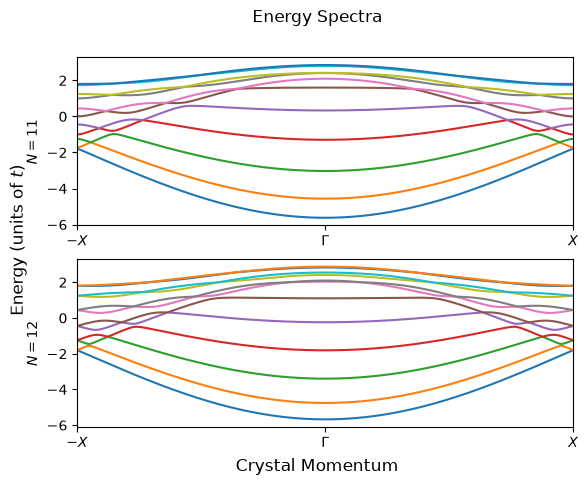

In [25]:
#Plotting

fig, (ax1,ax2) = plt.subplots(2)
for E in EoddT:
    ax1.plot(Xpath,E)

ax1.set_ylabel(f'$N={N_odd}$');
ax1.set_xlim(Xpoints[0],Xpoints[-1])
ax1.set_xticks(Xpoints,Knames);


for E in EevenT:
    ax2.plot(Xpath,E)
ax2.sharex(ax1)
ax2.set_ylabel(f'$N={N_even}$');

fig.suptitle('Energy Spectra');
fig.supylabel(r'Energy (units of $t$)');
fig.supxlabel('Crystal Momentum');

In [127]:
#Number of atoms going across the ribbon

N_odd = 201
N_even = N_odd+1

# Solving for E for the Odd N
Eodd = [[] for k in Kpath]
Codd = [[] for k in Kpath]

for i,k in enumerate(Kpath):
    try:
        Eodd[i],Codd[i] = eigh(T(k,N_odd))
    except LinAlgError:
        Eodd[i],Codd[i] = [float('nan') for _ in range(N_odd)]
Eodd = np.array(Eodd)
Codd = np.array(Codd)
EoddT = np.transpose(Eodd)
CoddT = np.transpose(Codd)

# Even N
Eeven = [[] for k in Kpath]
Ceven = [[] for k in Kpath]
for i,k in enumerate(Kpath):
    try:
        Eeven[i],Ceven[i] = eigh(T(k,N_even))
    except LinAlgError:
        Eeven[i],Ceven[i] = [float('nan') for _ in range(N_even)]
Eeven = np.array(Eeven)
Ceven = np.array(Ceven)
EevenT = np.transpose(Eeven)
CevenT = np.transpose(Ceven)

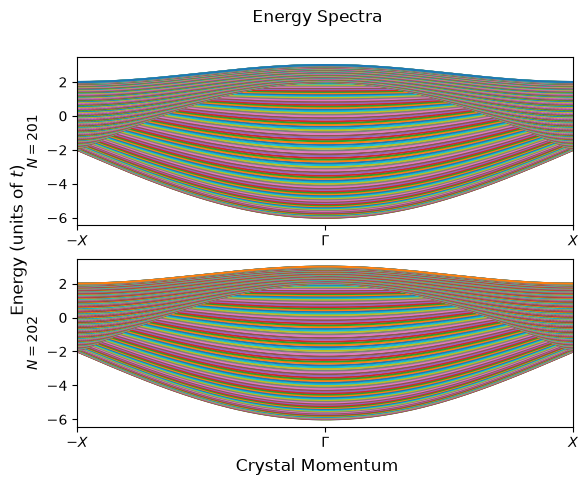

In [28]:
#Plotting

fig, (ax1,ax2) = plt.subplots(2)
for E in EoddT:
    ax1.plot(Xpath,E)

ax1.set_ylabel(f'$N={N_odd}$');
ax1.set_xlim(Xpoints[0],Xpoints[-1])
ax1.set_xticks(Xpoints,Knames);


for E in EevenT:
    ax2.plot(Xpath,E)
ax2.sharex(ax1)
ax2.set_ylabel(f'$N={N_even}$');

fig.suptitle('Energy Spectra');
fig.supylabel(r'Energy (units of $t$)');
fig.supxlabel('Crystal Momentum');

In [33]:
CoddX = Codd[-1]**2
CoddGamma = Codd[499]**2
CoddHalf = Codd[749]**2

CevenX = Ceven[-1]**2
CevenGamma = Ceven[499]**2
CevenHalf = Ceven[749]**2

In [ ]:
noddgridN,noddgridK = np.meshgrid(np.arange(N_odd),Kpath)
NevengridN,NevengridK = np.meshgrid(np.arange(N_even),Kpath)


TypeError: linspace() missing 1 required positional argument: 'stop'

In [32]:
len(Codd)

1000

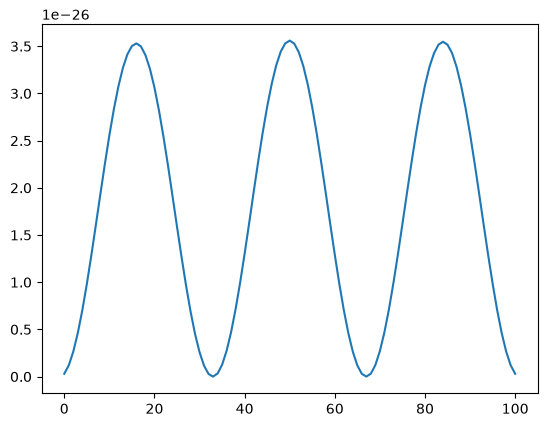

In [256]:
fig, ax = plt.subplots()
ax.plot(np.abs(CoddT[5,0::2,999]**2))

In [197]:
sum(np.abs(CevenT[100,:,499]**2))

np.float64(1.0000000000000004)

In [92]:
np.linspace(1,5,3)

array([1., 3., 5.])